## Assignment 1


### Exercise 3

In [19]:
library(readxl)
library(MASS)
library(goftest)

set.seed(1)   # reproducible tie-breaking jitter

## ---------------- Data ----------------
amazon <- read_excel("Amazon.xlsx")
logret <- as.numeric(na.omit(amazon$Logdailyreturn))
logret <- logret[is.finite(logret)]
logret <- logret + 1e-16 * rnorm(length(logret))   # break ties for KS
n <- length(logret)

## ---------------- (a) Normal: MLE + KS/AD ----------------
fit_n     <- fitdistr(logret, "normal")            # MLE (sd uses 1/n)
mu_hat    <- fit_n$estimate[["mean"]]
sigma_hat <- fit_n$estimate[["sd"]]
ll_n      <- fit_n$loglik

ks_n <- ks.test(logret, "pnorm", mean = mu_hat, sd = sigma_hat)
ad_n <- goftest::ad.test(logret, null = "pnorm", mean = mu_hat, sd = sigma_hat,
                         estimated = TRUE)          # corrected for estimated params
ks_n; ad_n

## ---------------- (b) General-t: MLE + KS/AD ----------------
# Location-scale t density: f(x) = (1/s) * t_df((x - m) / s)
dgt <- function(x, m, s, df) dt((x - m) / s, df) / s

# Fit on returns in % for numerically stable gradients, then rescale back
y <- 100 * logret
fit_y <- fitdistr(y, densfun = dgt,
                  start = list(m = median(y), s = IQR(y) / 2, df = 5),
                  lower = c(-Inf, 1e-6, 1))

est  <- fit_y$estimate
mle  <- c(m = est[["m"]] / 100, s = est[["s"]] / 100, df = est[["df"]])
se   <- c(m = fit_y$sd[["m"]] / 100, s = fit_y$sd[["s"]] / 100, df = fit_y$sd[["df"]])
ll_t <- fit_y$loglik + n * log(100)                 # Jacobian correction to original scale
mle; se

pgt  <- function(q) pt((q - mle[["m"]]) / mle[["s"]], df = mle[["df"]])
ks_t <- ks.test(logret, pgt)
ad_t <- goftest::ad.test(logret, null = pgt)        # params treated as fixed (conservative)
ks_t; ad_t

## ---------------- Comparison table ----------------
tab <- data.frame(
  Normal = c(mu_hat,     fit_n$sd[["mean"]],
             sigma_hat,  fit_n$sd[["sd"]],
             NA,         NA,
             sigma_hat,
             ll_n, 2*2 - 2*ll_n, 2*log(n) - 2*ll_n,
             ks_n$statistic, ks_n$p.value,
             ad_n$statistic, ad_n$p.value),
  t      = c(mle[["m"]], se[["m"]],
             mle[["s"]], se[["s"]],
             mle[["df"]], se[["df"]],
             mle[["s"]] * sqrt(mle[["df"]] / (mle[["df"]] - 2)),
             ll_t, 2*3 - 2*ll_t, 3*log(n) - 2*ll_t,
             ks_t$statistic, ks_t$p.value,
             ad_t$statistic, ad_t$p.value),
  row.names = c("Location (mean / m)", "SE location",
                "Scale (sd / s)",      "SE scale",
                "df",                  "SE df",
                "Implied SD of returns",
                "Log-likelihood", "AIC", "BIC",
                "KS statistic D", "KS p-value",
                "AD statistic A2", "AD p-value")
)

signif(tab, 5)


	Asymptotic one-sample Kolmogorov-Smirnov test

data:  logret
D = 0.080298, p-value = 4.294e-13
alternative hypothesis: two-sided



	Anderson-Darling test of goodness-of-fit
	Braun's adjustment using 48 groups
	Null hypothesis: Normal distribution
	with parameters mean = 0.00101906619342276, sd = 0.019319096403133
	Parameters assumed to have been estimated from data

data:  logret
Anmax = 3.7737, p-value = 0.4223


m           s          df 
0.001206624 0.012294348 3.234495429

m            s           df 
0.0003140759 0.0003277065 0.2356545868


	Asymptotic one-sample Kolmogorov-Smirnov test

data:  logret
D = 0.014226, p-value = 0.7498
alternative hypothesis: two-sided



	Anderson-Darling test of goodness-of-fit
	Null hypothesis: distribution ‘pgt’
	Parameters assumed to be fixed

data:  logret
An = 0.47175, p-value = 0.7758


,Normal,t
,<dbl>,<dbl>
Location (mean / m),1.0191e-03,1.2066e-03
SE location,4.0620e-04,3.1408e-04
Scale (sd / s),1.9319e-02,1.2294e-02
SE scale,2.8723e-04,3.2771e-04
df,NA,3.2345e+00
SE df,NA,2.3565e-01
Implied SD of returns,1.9319e-02,1.9901e-02
Log-likelihood,5.7177e+03,5.9985e+03
AIC,-1.1431e+04,-1.1991e+04


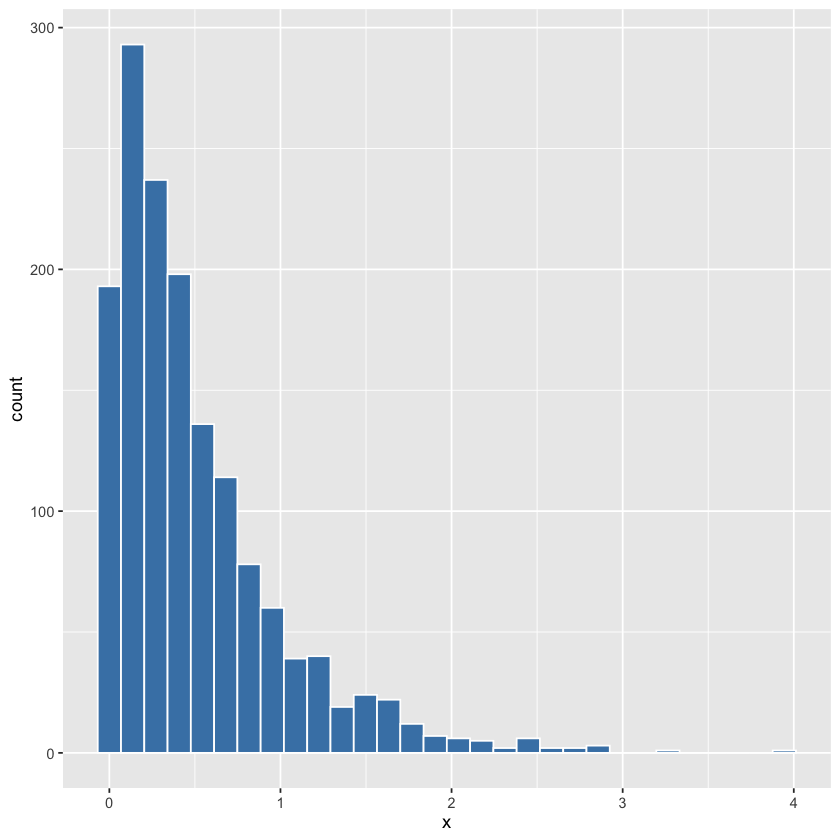

In [ ]:
# Exercise 4
library(ggplot2)
data <- read_excel("MATH4515_HW1_Data1.xlsx")
ggplot(data, aes(x = x)) + geom_histogram(bins = 30, fill = "steelblue", color = "white")




In [38]:
# Fitting the sample to a function using MLE
library(MASS)
f <- function(x, lambda){
    lambda * exp(-lambda * x)
}
fit <- fitdistr(data$x, f, start = list(lambda = 1 / mean(data$x)), method = "Brent", lower = 1e-8, upper = 100)
lambda_hat <- fit$estimate
lambda_se <- fit$sd
lambda_hat; lambda_se
ks_test <- ks.test(data$x, pexp, rate = lambda_hat)
ks_test$p.value 
cat("We fail to reject the null hypothesis that the data follows exponential distribution with rate = ", lambda_hat, "\nThe p-value is", ks_test$p.value )

[1] 1.992772

[1] 0.05145315

[1] 0.4312615

We fail to reject the null hypothesis that the data follows exponential distribution with rate =  1.992772 
The p-value is 0.4312615

Based on the KS-test we reject the null hypothesis that it follows the normal distribution as the p-value is 1.052125e-31

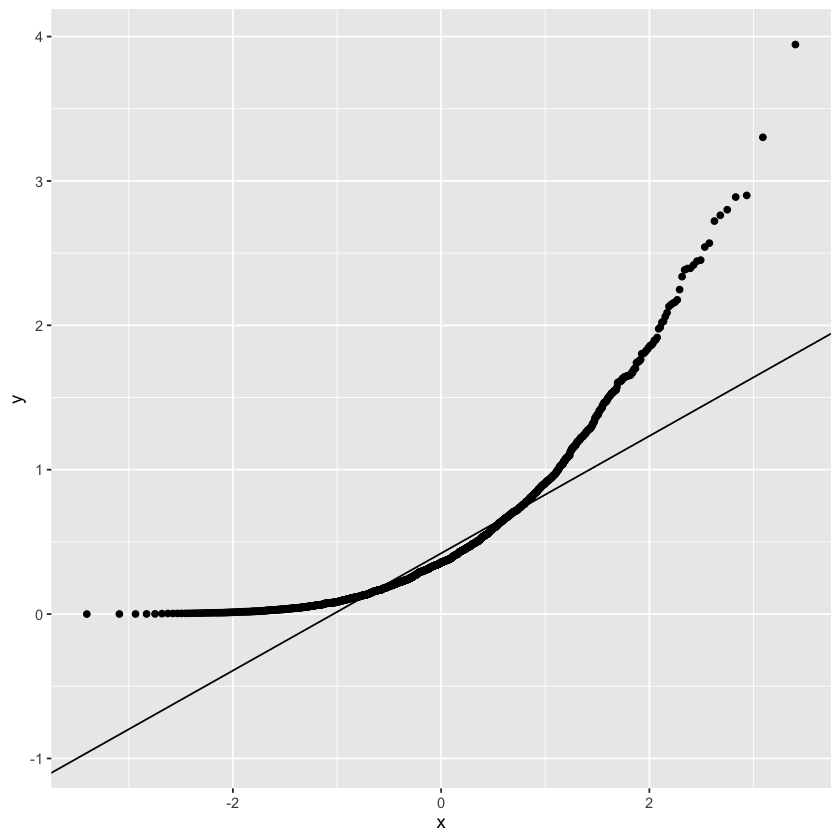

In [52]:
# Test the fit assuming normal distribution
fit_norm <- fitdistr(data$x, "normal")
mu_hat <- fit_norm$estimate["mean"]
sigma <- fit_norm$estimate["sd"]

ks_test <- ks.test(data$x, pnorm, mean = mu_hat, sd = sigma)
cat("Based on the KS-test we reject the null hypothesis that it follows the normal distribution as the p-value is", ks_test$p.value)

ggplot(data, aes(sample = x)) + stat_qq() + stat_qq_line()


In [57]:
# Bonus exercise: Using ad-hoc methods to calculate MLE

data2 <- read_excel("MATH4515_HW1_Data2.xlsx")
 
func_a <- function(x, theta){
    2 * theta ** 2 / (x + theta) ** 3
}

loglik_a <- function(x, theta){
    logfunc <- 2 * log(2*theta) - 3 * log(x + theta)
    loglike <- sum(logfunc)
    return (loglike)
}

sample_values <- seq(0.001, 10, by = 0.001)

ad_hoc_alg <- function(data, sample_values, loglik_func){
    n <- length(sample_values)
    loglik_list <- rep(1,n)
    for (i in 1:n){
        loglik_list[i] <- loglik_func(data, sample_values[i])
    }
    imax <- which.max(loglik_list)
    mle_value <- sample_values[imax]
    return(mle_value)
} 
cat("The MLE of theta =", ad_hoc_alg(data2$x, sample_values, loglik_a))

The MLE of theta = 1.001

In [62]:
data3 <- read_excel("MATH4515_HW1_Data3.xlsx")
data3 <- na.omit(data3)

func_b <- function(y, alpha, theta){
    alpha * theta ** alpha / (y + theta) ** (alpha + 1)
}

# Fix theta and calculate partial derivative wrt alpha
alpha_opt <- function(data, theta){
    n <- length(data)
    alpha <- (sum(log(data + theta) / n) - log(theta)) ** (-1)
    return (alpha)
}

loglik_b <- function(x, theta, alpha){
    logfunc <- log(alpha) + alpha * log(theta) - (alpha + 1) * log(x + theta)
    loglike <- sum(logfunc)
    return (loglike)
}

theta_values <- seq(0.001, 10, 0.001)
m <- length(theta_values)
alpha_values <- rep(1, m)
loglik_values <- rep(1, m)

# Determine which set of (theta, alpha) that maximizes the likelihood function after using the alpha that maximizes it likelihood after fixing theta
for (i in 1:m){
    alpha_optimal <- alpha_opt(data3$x, theta_values[i])
    loglik_values[i] <- loglik_b(data3$x, theta_values[i], alpha_optimal)
}
imax <- which.max(loglik_values)
theta_mle <- theta_values[imax]
alpha_mle <- alpha_opt(data3$x, theta_mle)

cat("The MLE estimates are \nAlpha = ", alpha_mle,"\nTheta = ", theta_mle )


The MLE estimates are 
Alpha =  2.794156 
Theta =  9.663